<a href="https://colab.research.google.com/github/NishantLaata/Credit_risk_analysis/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install ucimlrepo pandas numpy matplotlib seaborn

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Download the UCI Credit Card Default dataset
credit_data = fetch_ucirepo(id=350)

# Extract features and target
X = credit_data.data.features
y = credit_data.data.targets

# Combine into one DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset downloaded successfully!
Dataset shape: (30000, 24)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:
##age and defaulters

In [11]:
age_defaulters = df.groupby('X5')['Y'].agg(total_counts='count',defaulters= 'sum', default_rate='mean')

In [12]:
age_defaulters

,total_counts,defaulters,default_rate
X5,,,
21,67,14,0.208955
22,560,169,0.301786
23,931,247,0.265306
24,1127,300,0.266193
25,1186,302,0.254637
26,1256,253,0.201433
27,1477,313,0.211916
28,1409,286,0.202981
29,1605,313,0.195016


In [16]:
## Age distribution Visualization

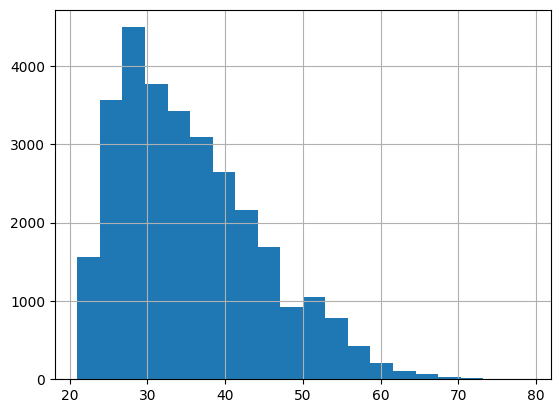

In [21]:
age_distribution_hist = df['X5'].hist(bins=20)

In [13]:
agender_defaulters = df.groupby('X2')['Y'].agg(total_counts = 'count',defaulters ='sum',default_rate='mean')

This research employed a binary variable, default payment (Yes = 1, No = 0), as the response variable. This study reviewed the literature and used the following 23 variables as explanatory variables: X1: Amount of the given credit (NT dollar): it includes both the individual consumer credit and his/her family (supplementary) credit. X2: Gender (1 = male; 2 = female). X3: Education (1 = graduate school; 2 = university; 3 = high school; 4 = others). X4: Marital status (1 = married; 2 = single; 3 = others). X5: Age (year). X6 - X11: History of past payment. We tracked the past monthly payment records (from April to September, 2005) as follows: X6 = the repayment status in September, 2005; X7 = the repayment status in August, 2005; . . .;X11 = the repayment status in April, 2005. The measurement scale for the repayment status is: -1 = pay duly; 1 = payment delay for one month; 2 = payment delay for two months; . . .; 8 = payment delay for eight months; 9 = payment delay for nine months and above. X12-X17: Amount of bill statement (NT dollar). X12 = amount of bill statement in September, 2005; X13 = amount of bill statement in August, 2005; . . .; X17 = amount of bill statement in April, 2005. X18-X23: Amount of previous payment (NT dollar). X18 = amount paid in September, 2005; X19 = amount paid in August, 2005; . . .;X23 = amount paid in April, 2005.

In [28]:
## Gender Defaulters

In [29]:
gender_defaulters

,total_counts,defaulters,default_rate
X2,,,
1,11888,2873,0.241672
2,18112,3763,0.207763


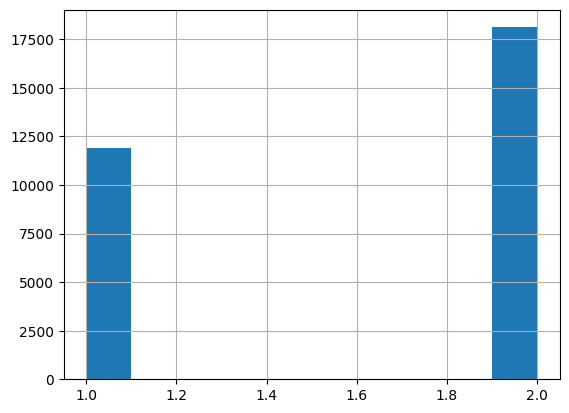

In [27]:
gender_distribution_hist = df['X2'].hist()

In [30]:
## Data analysis

In [34]:
# Average credit limit across all customers
average_credit_limit = df['X1'].mean()

In [32]:
average_credit_limit

np.float64(167484.32266666667)

In [36]:
# Distribution of customer credit limit
credit_limit_distribution = df['X1'].value_counts()
credit_limit_distribution

,count
X1,
50000,3365
20000,1976
30000,1610
80000,1567
200000,1528
...,...
800000,2
1000000,1
327680,1


In [41]:
# credit limit defaulters
credit_limit_defaulters = df.groupby('X1')['Y'].agg(total = 'count', default_rate='mean', defaulters = 'sum')
credit_limit_defaulters


,total,default_rate,defaulters
X1,,,
10000,493,0.399594,197
16000,2,0.000000,0
20000,1976,0.353239,698
30000,1610,0.352795,568
40000,230,0.400000,92
...,...,...,...
750000,4,0.000000,0
760000,1,0.000000,0
780000,2,0.000000,0


In [37]:
## ML starts here

In [42]:
df.shape

(30000, 24)

In [43]:
df.isna().sum()

,0
X1,0
X2,0
X3,0
X4,0
X5,0
X6,0
X7,0
X8,0
X9,0
X10,0


In [46]:
df.dtypes

,0
X1,int64
X2,int64
X3,int64
X4,int64
X5,int64
X6,int64
X7,int64
X8,int64
X9,int64
X10,int64


In [54]:
df.duplicated().sum()

np.int64(35)

In [51]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
29995,False
29996,False
29997,False
29998,False


In [53]:
df.nunique().sum()

np.int64(174606)

In [57]:
independent_var = df.drop(columns='Y')

In [62]:
dependent_var = df.loc[:, ~df.columns.str.startswith('X')]


In [63]:
dependent_var

,Y
0,1
1,1
2,0
3,0
4,0
...,...
29995,0
29996,0
29997,1
29998,1
